# Formulas for $R_{p/2}$ and self-consistent equation for F($\Lambda$)

In [26]:
import numpy as np
from scipy.integrate import quad
from math import comb
from scipy.interpolate import CubicSpline
import csv
import matplotlib.pyplot as plt
 
LIMIT = 200
#Distribution for the intrinsic frequencies w
def g_gauss(w, varsigma=1.0):
    """ g(w) being Gaussian """
    w = np.asarray(w, float)
    return np.exp(-0.5 * (w / varsigma) ** 2) / (varsigma * np.sqrt(2.0 * np.pi))
def g_lor(w, Delta=1.0):
    """ g(w) being Lorentzian """
    w = np.asarray(w, float)
    return (Delta / np.pi) / (w ** 2+ Delta ** 2)
    
# General R_p/2 for all distributions.
def S(w, Lam):
    """ Formula for S, a term appears in all R_p """
    return np.sqrt(np.abs(1.0 - (w / Lam) ** 2))
def R_h(Lam, g, eta):
    """ R_{1/2} """
    if Lam <= 0.0:
        return 0.0
    f = lambda w: g(w) * np.sqrt(0.5 * (1.0 + S(w, Lam)))
    return (2 * eta - 1) * quad(f, -Lam, Lam, points=[0.0], limit=LIMIT)[0]
def R_1(Lam, g):
    """ R_1 """
    if Lam <= 0.0:
        return 0.0
    f = lambda w: g(w) * S(w, Lam)
    return quad(f, -Lam, Lam, points=[0.0], limit=LIMIT)[0]
def R_1h(Lam, g, eta):
    """ R_{3/2} """
    if Lam <= 0.0:
        return 0.0
    f = lambda w: g(w) * (2.0 * S(w, Lam) - 1.0) * np.sqrt(0.5 * (1.0 + S(w, Lam)))
    return (2 * eta - 1) * quad(f, -Lam, Lam, points=[0.0], limit=LIMIT)[0]
def R_2(Lam, g):
    """ R_2 """
    if Lam <= 0.0:
        return 0.0
    f1 = lambda w: g(w) * (1.0 - 2.0 * (w / Lam) ** 2)
    f2 = lambda w: g(w) * (1.0 - 2.0 * (w / Lam) ** 2 + 2.0 * abs(w / Lam) *  S(w, Lam))
    inner = quad(f1, -Lam, Lam, points=[0.0], limit=LIMIT)[0]
    outer = (quad(f2, Lam, np.inf, limit=LIMIT)[0])
    return inner + 2.0 * outer
def R_2h(Lam, g, eta):
    """ R_{5/2} """
    if Lam <= 0.0:
        return 0.0
    f = lambda w: g(w) * (3.0 - 4.0 * (w / Lam) ** 2 - 2.0 * S(w, Lam)) * np.sqrt(0.5 * (1.0 + S(w, Lam)))
    return (2 * eta - 1) * quad(f, -Lam, Lam, points=[0.0], limit=LIMIT)[0]
def R_3(Lam, g):
    """ R_3 """
    if Lam <= 0.0:
        return 0.0
    f = lambda w: g(w) * (1.0 - 4.0 * (w / Lam) ** 2) * S(w, Lam)
    return quad(f, -Lam, Lam, points=[0.0], limit=LIMIT)[0]
R_d = {1: R_h, 2: R_1, 3: R_1h, 4: R_2, 5: R_2h, 6: R_3}
def R(p, Lam, g, eta=None):
    """ returns exact value for R_p with given Lambda, distribution (and eta). """
    p = abs(p)                      # R_{-p/2} = R_{p/2}
    if p == 0:
        return 1
    if p % 2 == 1:              # half integer moments carry (2*eta - 1)
        return R_d[p](Lam, g, eta)
    return R_d[p](Lam, g)

#For M = 2 case
def F2(Lam, h, s1, s2, g, eta=None):
    """ The self-consistent function for M = 2 """
    r = lambda i: R(i, Lam, g, eta)
    Theta_2 = 0.0
    for n in range(h + 1):
        Theta_2 += comb(h, n) * r(2 * n - h + 1) * r(2 * n - h - 1)
    return  s1 * r(2) + s2 / 2 ** h * Theta_2

def F3(Lam, h1, h2, s1, s2, s3, g, eta=None):
    """ The self-consistent function for M = 3 """
    r = lambda i: R(i, Lam, g, eta)
    Theta_2 = 0.0
    Theta_3 = 0.0
    for n in range(h1 + 1):
        Theta_2 += comb(h1, n) * r(2 * n - h1 + 1) * r(2 * n - h1 - 1)
    for n in range(h1):
        for m in range(h2):
            Theta_3 += comb(h1-1, n) * comb(h2-1, m) * r(1-2*n+h1) * r(2*n-2*m-h1+h2) * r(2*m-h2+1)
    return  s1 * r(2) + s2 / 2 ** h1 * Theta_2 + s3 / 2 ** (h1+h2-2) * Theta_3

# Solving self-consistent function

In [21]:
# Performing quad to every choice of s1, s2, Lam is expensive
# We do interpolation for every (h, g, eta) for R(Lambda) and F(Lambda, s1, s2)
LAM_MIN = 1e-3
ITP_MIN = 1e-3
LAM_MAX = 50.0
ITP_MAX = 50.0
N_NODE  = 400
 
k     = 0.5
MAX_ITER  = 2000
 
 
def solve_damped(Lam0, F, *args, k=0.5, max_iter=MAX_ITER, tol=1e-6):
    """
    Damping iteration for Lambda_n+1 = Lambda_n + k * (F(Lambda_n) - Lambda_n)

    Input:
        Lam0: initial Lambda
        F: self-consistant funciton, F2 or F3
        args: arguments for F2 or F3

    Return:
        Lam which is solves Lambda in the function Lambda = F(Lambda)
    """
    Lam = Lam0
    for n in range(1, max_iter):
        d = F(Lam, *args) - Lam
        Lam  = max(Lam + k * d, 0.0)
        if abs(d) < tol:
            return Lam
    return Lam

# Synchronization and desynchronization for the model

In [10]:
sigma1_sweep = np.linspace(-10.0, 10.0, 1001)
 
 
def syn_desyn(Lam0, M, g, eta, sigma1_sweep, s2, s3, h1, h2, Lam_sync = 50):
    """
    Compute the order parameter for synchronization/desynchronization with given parameters.


    Input:
    Lam0: small positive real value. initial Lambda
    M: order of the model, 2 or 3.
    g: distribution function, g_gauss or g_lor
    eta: real number in [0,1], bias
    sigma1_sweep: list for sigma1 to sweep
    s2: float, coupling constant for triangles
    s3: float, coupling constant for tetrahedron, could be None
    h1: integer. f1(x) = cos(x)^(h1-1)
    h2: integer. f2(x) = cos(x)^(h2-1)
    
    

    Output:
    Rup: List of order parameter for synchronization
    Rdown: List of order parameter for desynchronization


    """

    Rup = []
    Rdown = []
    Lam = Lam0

    if M == 2:
        F, pre, post = F2, (h1,), (s2, g, eta)
    else:
        F, pre, post = F3, (h1, h2), (s2, s3, g, eta)
        
    for i in range(len(sigma1_sweep)):
        s1 = sigma1_sweep[i]
        Lam = solve_damped(max(Lam, Lam0), F, *pre, s1, *post) 
        Rup.append(R_1(Lam, g))
        #Add a small perturbation if incoherent 
        if abs(Lam) < 1e-10:
            Lam = Lam0 
            
    #Seperate desync and syn when initial frequencies are biased
    if (M ==2 and h1 % 2 == 0) or (M == 3 and h1 * h2 % 2 != 1):
        Lam = Lam_sync 

    for i in range(len(sigma1_sweep)):
        s1 = sigma1_sweep[len(sigma1_sweep)-i-1]
        Lam = solve_damped(Lam, F, *pre, s1, *post)
        Rdown.append(R_1(Lam,g))
    Rdown.reverse()
    return Rup, Rdown

# Visulization of dynamical state: a plot of order parameter against sigma1

## $M = 2, h_1 = 5, \sigma_2 = 10$, hysteresis loop exists for $\omega$ being Gaussian-distributed

In [19]:
#syn_desyn(Lam0, M, g, eta, sigma1_sweep, s2, s3, h1, h2, Lam_sync = 50)
Rup_2_5_10, Rdown_2_5_10 = syn_desyn(0.01, 2, g_gauss, None, sigma1_sweep, 10, None, 5, None, Lam_sync = 50)

/var/folders/m7/szqjqt0174nfl5dz1w24ytlh0000gp/T/ipykernel_63885/335610088.py:48: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  outer = (quad(f2, Lam, np.inf, limit=LIMIT)[0])
/var/folders/m7/szqjqt0174nfl5dz1w24ytlh0000gp/T/ipykernel_63885/335610088.py:48: IntegrationWarning: The maximum number of subdivisions (200) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  outer = (quad(f2, Lam, np.inf, limit=LIMIT)[0])


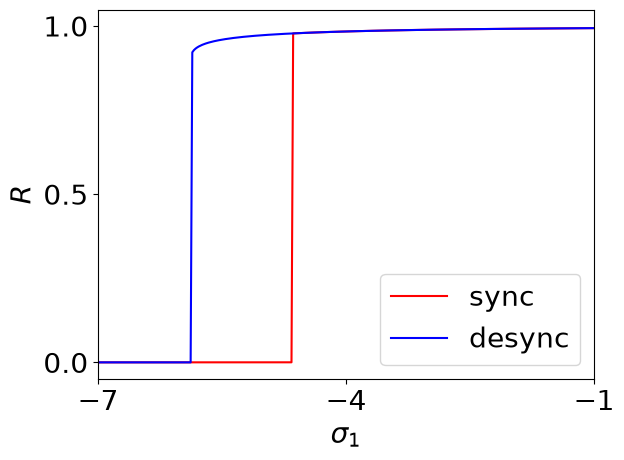

In [35]:
plt.plot(sigma1_sweep, Rup_2_5_10, color="red", label="sync")
plt.plot(sigma1_sweep, Rdown_2_5_10, color="blue", label="desync")
plt.xlim((-7, -1))
plt.xticks([-7, -4, -1], fontsize=20)
plt.yticks([0, 0.5, 1], fontsize=20)
plt.legend(fontsize=20)
plt.xlabel(r"$\sigma_1$", fontsize=20)
plt.ylabel(r"$R$", fontsize=20)
plt.show()

## $M = 2, h_1 = 4, \sigma_2 = 3$, $\omega$ being Gaussian-distributed. Comparisons with different biases $\eta$

In [29]:
#syn_desyn(Lam0, M, g, eta, sigma1_sweep, s2, s3, h1, h2, Lam_sync = 50)
_ , Rdown_2_4_3_06 = syn_desyn(0.01, 2, g_gauss, 0.6, sigma1_sweep, 3, None, 4, None, Lam_sync = 50)
_ , Rdown_2_4_3_1 = syn_desyn(0.01, 2, g_gauss, 1, sigma1_sweep, 3, None, 4, None, Lam_sync = 50)

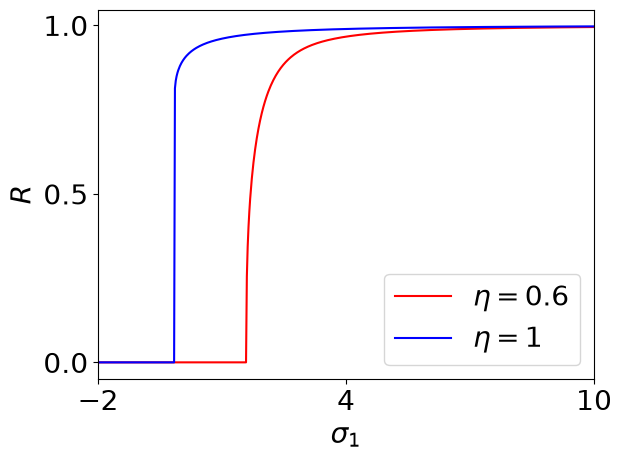

In [36]:
plt.plot(sigma1_sweep, Rdown_2_4_3_06, color="red", label=r"$\eta = 0.6$")
plt.plot(sigma1_sweep, Rdown_2_4_3_1, color="blue", label=r"$\eta = 1$")
plt.xlim((-2, 10))
plt.xticks([-2, 4, 10], fontsize=20)
plt.yticks([0, 0.5, 1], fontsize=20)
plt.legend(fontsize=20)
plt.xlabel(r"$\sigma_1$", fontsize=20)
plt.ylabel(r"$R$", fontsize=20)
plt.show()

## $M = 3, h_1 = 5, h_2 = 2, \sigma_2 = -0.5, \sigma_3 = 5$, $\omega$ being Gaussian-distributed. Comparisons with different biases $\eta$

In [37]:
#syn_desyn(Lam0, M, g, eta, sigma1_sweep, s2, s3, h1, h2, Lam_sync = 50)
_ , Rdown_M3_06 = syn_desyn(0.01, 3, g_gauss, 0.6, sigma1_sweep, -0.5, 5, 5, 2, Lam_sync = 50)
_ , Rdown_M3_1 = syn_desyn(0.01, 3, g_gauss, 1, sigma1_sweep, -0.5, 5, 5, 2, Lam_sync = 50)

/var/folders/m7/szqjqt0174nfl5dz1w24ytlh0000gp/T/ipykernel_63885/335610088.py:48: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  outer = (quad(f2, Lam, np.inf, limit=LIMIT)[0])
/var/folders/m7/szqjqt0174nfl5dz1w24ytlh0000gp/T/ipykernel_63885/335610088.py:48: IntegrationWarning: The maximum number of subdivisions (200) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  outer = (quad(f2, Lam, np.inf, limit=LIMIT)[0])


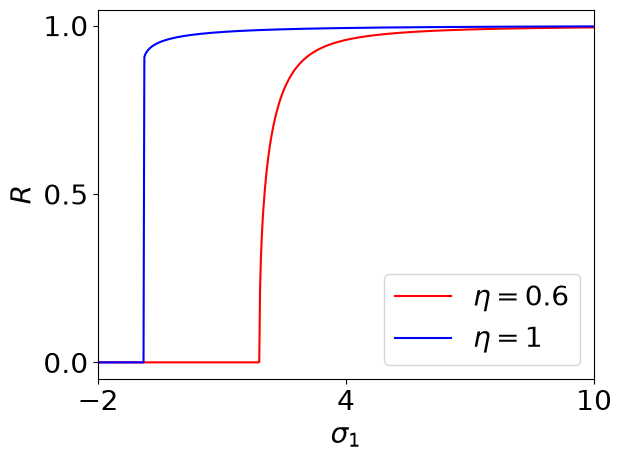

In [38]:
plt.plot(sigma1_sweep, Rdown_M3_06, color="red", label=r"$\eta = 0.6$")
plt.plot(sigma1_sweep, Rdown_M3_1, color="blue", label=r"$\eta = 1$")
plt.xlim((-2, 10))
plt.xticks([-2, 4, 10], fontsize=20)
plt.yticks([0, 0.5, 1], fontsize=20)
plt.legend(fontsize=20)
plt.xlabel(r"$\sigma_1$", fontsize=20)
plt.ylabel(r"$R$", fontsize=20)
plt.show()

# Phase Diagram for $M = 3$, Fig 6

In [87]:
# Settings
M = 3
h1 = 5
h2 = 2
s3 = 5
eta = 0.8
g = g_gauss
etas = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
tol = 1e-6
sigma1_sweep = np.linspace(-10.0, 10.0, 2001)

## Transcritical Line

In [88]:
def transcritical(F3, h1, h2, sigma1_sweep, s3, g, eta):
    '''
    Transcritical line is the solution to F3'(Lam = 0) = 1.
    Supercritical: F3''(Lambda = 0) < 0
    Subcritical: F3''(Lambda = 0) > 0

    Input:
    F3: Self-consistent function
    Lam, h1, h2, sigma1_sweep, s3, g, eta arguments for F3

    Output:
    dF: function: first derivative with fixed h1, h2, s3.
    ddF: function: second derivative with fixed h1, h2, s3.
    dddF: function: third derivative with fixed h1, h2, s3.
    Sub_lines: List of (σ1,σ2) which are subcritical
    Sup_lines: List of (σ1,σ2) which are supercritical
    trans_lines: List of (σ1,σ2) which are transcritical
    '''

    eps = 1e-3
    tol = 1e-6
    f = lambda Lambda, s1, s2, s3: F3(Lambda, h1, h2, s1, s2, s3, g, eta)
    #F'(0) = (-3F(0) + 4F(ε) - F(2ε))/2ε
    dF = lambda s1, s2, s3: (4 * f(eps, s1, s2, s3)  - f(2 * eps,s1, s2, s3)) / (2 * eps)
    #F'(0) = σ1*T1 + σ2*T2 + σ3*T3
    T1 = dF(1,0,0)
    T2 = dF(0,1,0)
    T3 = dF(0,0,1)

    #Solving F'(0) = 1 gives σ1*T1 + σ2*T2 + σ3*T3 = 1, so σ2 = (1-σ1*T1 - σ3*T3)/T2
    #Get the list sigma_1sweep (σ1) x transcritical_line (σ2)
    transcritical_line = (1 - T1*sigma1_sweep - T3 * s3) / T2

    #Second derivative
    #F''(0) = (2F(0) - 5F(ε) + 4F(2ε) - F(3ε))/ε^2
    ddF = lambda s1, s2, s3: (-5 * f(eps, s1, s2, s3) + 4 * f(2 * eps, s1, s2, s3) - f(3 * eps, s1, s2, s3))/(eps **2)

    #Third derivative
    #F'''(0) = (-F(0) + 3F(ε) - 3F(2ε) + F(3ε))/ε^3
    dddF = lambda s1, s2, s3: (3 * f(eps, s1, s2, s3) - 3 * f(2 * eps, s1, s2, s3) + f(3 * eps, s1, s2, s3))/(eps **3)


    #distinguish sub/super critical points
    Sub_lines = []
    Sup_lines = []
    trans_lines = []
    for i in range(len(transcritical_line)):
        s2 = transcritical_line[i]
        s1 = sigma1_sweep[i]
        trans_lines.append((s1,s2))
        if abs(ddF(0, 1, 0)) > tol or abs(s3 * ddF(0, 0, 1)) > tol:
            if ddF(s1,s2,s3) < 0: 
                Sup_lines.append((s1,s2))
            else:
                Sub_lines.append((s1,s2))
        else:
            if dddF(s1,s2,s3) < 0: 
                Sup_lines.append((s1,s2))
            else:
                Sub_lines.append((s1,s2))
    return Sub_lines, Sup_lines, trans_lines

In [89]:
eta1 = 0.5
eta2 = 0.8
Sub_lines_05, Sup_lines_05, trans_lines_05 = transcritical(F3, h1, h2, sigma1_sweep, s3, g, eta1)
Sub_lines_08, Sup_lines_08, trans_lines_08 = transcritical(F3, h1, h2, sigma1_sweep, s3, g, eta2)

## Saddle-Node Curve

### Solving $\sigma_1R_1+\sigma_2 T_2 =\Lambda-\sigma_3T_3, \sigma_1R_1'+\sigma_2 T_2'=1-\sigma_3T_3' .$
### Get $$\sigma_1=\frac{(\Lambda-\sigma_3T_3)\,T_2'-(1-\sigma_3T_3')\,T_2}{R_1T_2'-R_1'T_2},\qquad \sigma_2=\frac{R_1\,(1-\sigma_3T_3')-R_1'\,(\Lambda-\sigma_3T_3)}{R_1T_2'-R_1'T_2}.$$

In [90]:
def SN(Lambda_sweep, F3, h1, h2, s3, g, eta):
    '''
    Given Lambda, finding corresponding (σ1,σ2) which solves the system F3(Lambda) = Lambda and F3'(Lambda) = 1

    Input:
    F3: Self-consistent function
    Lam, h1, h2, s3, g, eta: arguments for F3

    Output:
    SN_lines: List of (σ1,σ2) which makes up the saddle-node lines
    '''
    f = lambda Lambda, s1, s2, s3: F3(Lambda, h1, h2, s1, s2, s3, g, eta)
    eps = 1e-3
    SN_lines = []
    Det_old = 0
    for Lam in Lambda_sweep:
        R1 = f(Lam, 1, 0, 0)
        T2 = f(Lam, 0, 1, 0)
        T3 = f(Lam, 0, 0, 1)
        dR1 = (f(Lam + eps, 1, 0, 0) - f(Lam - eps, 1, 0, 0)) / (2 * eps)
        dT2 = (f(Lam + eps, 0, 1, 0) - f(Lam - eps, 0, 1, 0)) / (2 * eps)
        dT3 = (f(Lam + eps, 0, 0, 1) - f(Lam - eps, 0, 0, 1)) / (2 * eps)
        Det = R1 * dT2 - dR1 * T2
        #Change of the sign of the determinant
        if Det * Det_old < 0:
            break
        s1 = ((Lam - s3 * T3) * dT2 - (1 - s3 * dT3) * T2) / Det
        s2 = (R1 * (1 - s3 * dT3) - dR1 * (Lam - s3 * T3)) / Det
        SN_lines.append((s1,s2))
        Det_old = Det
    return SN_lines

In [91]:
Lambda_sweep = np.geomspace(1e-2, 30 + 30 + abs(s3), 200)
eta1 = 0.5
eta2 = 0.8
SN_lines_05 = SN(Lambda_sweep, F3, h1, h2, s3, g, eta1)
SN_lines_08 = SN(Lambda_sweep, F3, h1, h2, s3, g, eta2)

## Cusp points and grey points

### Cusp point: $F''(0)=0$ on the transcritical line (if always $F''(0)=0$ on the whole transcritical line, then $F'''(0)=0$ instead).
### Grey point: When $F''(0)>0$, the point of $F'''(0)=0$ on the line ($\eta$ matters).

In [100]:
def important_points(trans_lines, Sub_lines, Sup_lines, F3, h1, h2, s3, g, eta):
    '''
    Find the cusp points, and the dddF(0) = 0 point, when ddF(0) > 0 for each eta

    Input:
    trans_lines: List of (σ1,σ2) which are transcritical
    Sub_lines: List of (σ1,σ2) which are subcritical
    Sup_lines: List of (σ1,σ2) which are supercritical
    F: function
    s3: coupling constant for tetrahedron

    Output:
    Cusp: tuple(σ1,σ2) or None
    Grey: tuple(σ1,σ2) such that dddF(0) = 0 for ddF(0) > 0 or None
    '''


    Cusp = None
    Grey = None

    eps = 1e-3
    f = lambda Lambda, s1, s2, s3: F3(Lambda, h1, h2, s1, s2, s3, g, eta)
    dddF = lambda s1, s2, s3: (3 * f(eps, s1, s2, s3) - 3 * f(2 * eps, s1, s2, s3) + f(3 * eps, s1, s2, s3)) / (eps ** 3)


    #Cusp point: the meeting point for the sub/supercritical
    if len(Sub_lines) > 0 and len(Sup_lines) > 0:
        s11, s21 = Sub_lines[-1]
        s12, s22 = Sup_lines[0]
        Q1 = dddF(s11, s21, s3)
        Q2 = dddF(s12, s22, s3)
        t = Q1 / (Q1 - Q2)
        Cusp = (s11 + t * (s12 - s11), s21 + t * (s22 - s21))
        
    #Grey point: all subcritical (ddF(0) > 0), dddF(0) = 0
    elif len(Sup_lines) == 0:
        Q = [dddF(s1, s2, s3) for s1, s2 in trans_lines]
        for i in range(len(Q) - 1):
            if Q[i] * Q[i + 1] < 0:
                s11, s21 = trans_lines[i]
                s12, s22 = trans_lines[i + 1]
                t = Q[i] / (Q[i] - Q[i + 1])
                Grey = (s11 + t * (s12 - s11), s21 + t * (s22 - s21))
                break
    return Cusp, Grey

In [101]:
Cusp_05, Grey_05 = important_points(trans_lines_05, Sub_lines_05, Sup_lines_05, F3, h1, h2, s3, g, eta1)

In [102]:
Cusp_08, Grey_08 = important_points(trans_lines_08, Sub_lines_08, Sup_lines_08, F3, h1, h2, s3, g, eta2)

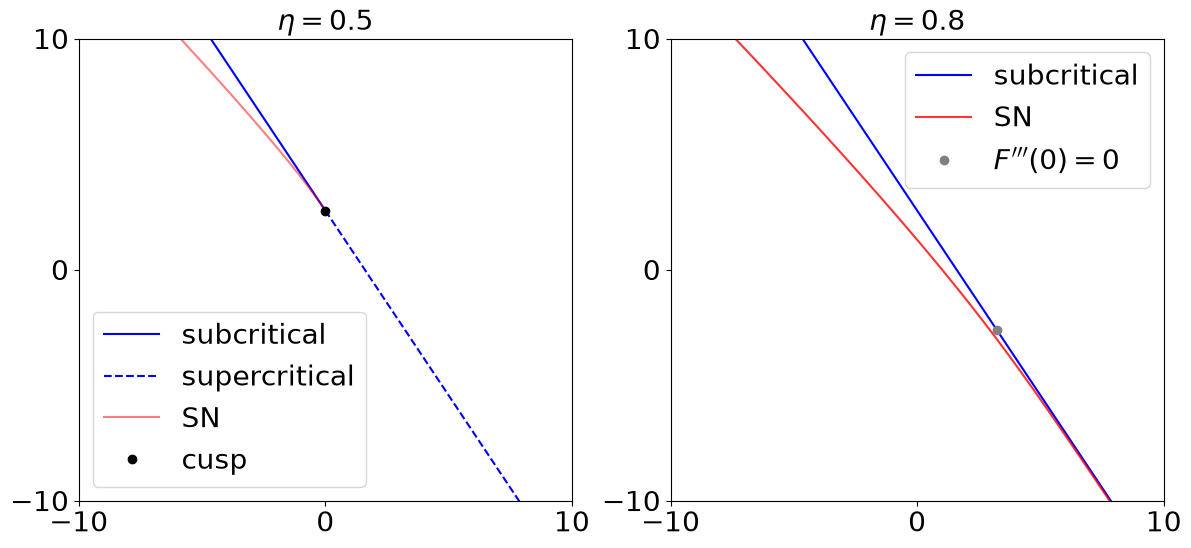

In [121]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
x, y = zip(*Sub_lines_05)
plt.plot(x, y, color='blue', label='subcritical')
x, y = zip(*Sup_lines_05)
plt.plot(x, y, color='blue', linestyle='--', label='supercritical')
x, y = zip(*SN_lines_05)
plt.plot(x, y, color='red', alpha=eta1, label='SN')
plt.plot(Cusp_05[0], Cusp_05[1], 'o', color='black', label='cusp')
plt.title(rf'$\eta = {eta1}$', fontsize=20)
plt.xlim(-10,10)
plt.ylim(-10,10)
plt.xticks([-10, 0, 10], fontsize=20)
plt.yticks([-10, 0, 10], fontsize=20)
plt.legend(fontsize=20)

plt.subplot(1, 2, 2)
x, y = zip(*Sub_lines_08)
plt.plot(x, y, color='blue', label='subcritical')
x, y = zip(*SN_lines_08)
plt.plot(x, y, color='red', alpha=eta2, label='SN')
plt.plot(Grey_08[0], Grey_08[1], 'o', color='grey', label="$F'''(0) = 0$")
plt.title(rf'$\eta = {eta2}$', fontsize=20)
plt.xlim(-10,10)
plt.ylim(-10,10)
plt.xticks([-10, 0, 10], fontsize=20)
plt.yticks([-10, 0, 10], fontsize=20)
plt.legend(fontsize=20)
plt.show()